# Beta-convergência absoluta entre os estados brasileiros, 2002–2023

Estima a beta-convergência absoluta por mínimos quadrados ordinários, com erros-padrão HC3, calcula a velocidade de convergência e a meia-vida e aplica as especificações de robustez (seção 4.2.1 do TCC).

Os dados vêm do Ipeadata e devem estar na pasta `../dados_usados` (ver o README do repositório).

In [1]:
# ----------------------------------------------------------------------------
# 1. BIBLIOTECAS E PARÂMETROS
# ----------------------------------------------------------------------------
import os                             # criação das pastas de saída
import numpy as np                    # operações numéricas; usamos np.log e np.exp
import pandas as pd                   # manipulação de tabelas (DataFrames)
import statsmodels.api as sm          # estimação por MQO com testes e erros robustos
from scipy import stats               # valores críticos da distribuição t
import matplotlib.pyplot as plt       # gráfico de dispersão

# Caminho do arquivo baixado do Ipeadata (série PIBPCE), guardado na pasta
# TCC\dados_usados. O ".." sobe da pasta deste notebook para a pasta TCC.
CAMINHO = os.path.join("..", "dados_usados",
                       "PIBPCE_pib_estadual_per_capita_precos_2010_[17-08-2026].csv")

# Parâmetros do estudo, declarados uma única vez para não repetir números soltos
ANO_INICIAL = 2002
ANO_FINAL   = 2023
TAU         = ANO_FINAL - ANO_INICIAL   # amplitude do período: 21 anos

# Tipo de erro-padrão robusto usado em todas as estimações.
# HC3 (Long e Ervin, 2000): versão recomendada para amostras pequenas. Divide cada
# resíduo ao quadrado por (1 - h_i)^2, em que h_i é a alavancagem da observação,
# o que dá mais peso aos resíduos dos pontos extremos (como o DF).
TIPO_EP = "HC3"

# Níveis de significância do teste unilateral
NIVEIS = [0.05, 0.01]

# Pastas onde os resultados são salvos. exist_ok=True evita erro se já existirem.
for pasta in ["resultados/figuras", "resultados/tabelas", "dados/tratados"]:
    os.makedirs(pasta, exist_ok=True)

In [2]:
# ----------------------------------------------------------------------------
# 2. LEITURA E LIMPEZA
# ----------------------------------------------------------------------------
# skiprows=1        -> o arquivo do Ipeadata traz o título da série na 1ª linha;
#                      o cabeçalho de verdade (Sigla, Código, Estado, 2002...) está na 2ª
# encoding='utf-8-sig' -> remove o BOM (caractere invisível no início do arquivo)
#                      que faria a 1ª coluna se chamar "﻿Sigla"
df = pd.read_csv(CAMINHO, skiprows=1, encoding="utf-8-sig")

# O arquivo termina cada linha com vírgula, o que cria uma coluna vazia extra
# chamada "Unnamed: 25". Esta linha mantém apenas as colunas com nome de verdade.
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

# Os anos vieram como nomes de coluna em texto ("2002", "2003", ...).
# Selecionamos apenas as colunas cujo nome é composto só de dígitos.
anos = [c for c in df.columns if c.isdigit()]

In [3]:
# ----------------------------------------------------------------------------
# 3. FORMATO LONGO (tidy)
# ----------------------------------------------------------------------------
# O arquivo está em formato "largo": um estado por linha, um ano por coluna.
# Para análise convém o formato "longo": uma linha por estado-ano.
# melt() empilha as colunas de ano em duas colunas: 'ano' e 'pibpc_real'.
painel = df.melt(
    id_vars=["Sigla", "Código", "Estado"],   # colunas que identificam a unidade
    value_vars=anos,                          # colunas que serão empilhadas
    var_name="ano",                           # nome da nova coluna com os anos
    value_name="pibpc_real",                  # nome da nova coluna com os valores
)

painel["ano"] = painel["ano"].astype(int)     # converte o ano de texto para inteiro

# Logaritmo natural do PIB per capita real.
# O log não é escolha estatística: a equação de convergência é derivada da
# log-linearização do modelo de Solow, portanto é em logs que ela deve ser estimada.
painel["ln_pibpc"] = np.log(painel["pibpc_real"])

# ---- Validações antes de prosseguir --------------------------------------
# Se qualquer uma falhar, há erro de leitura e não adianta seguir.
assert len(painel) == 27 * 22, f"Esperado 594 linhas, obtido {len(painel)}"
assert painel["Sigla"].nunique() == 27, "Não há 27 UF"
assert painel["pibpc_real"].isna().sum() == 0, "Há valores ausentes"
print(f"Painel validado: {len(painel)} observações, {painel['Sigla'].nunique()} UF, "
      f"{painel['ano'].min()}-{painel['ano'].max()}")

Painel validado: 594 observações, 27 UF, 2002-2023


In [4]:
# ----------------------------------------------------------------------------
# 4. BASE DA REGRESSÃO (corte transversal: 27 linhas, uma por estado)
# ----------------------------------------------------------------------------
# A regressão de beta-convergência NÃO usa o painel inteiro. Ela usa apenas dois
# pontos no tempo por estado: o inicial e o final. O painel completo serve para a
# sigma-convergência e para as cadeias de Markov.

# pivot() volta ao formato largo, mas agora com os logs
larga = painel.pivot(index="Sigla", columns="ano", values="ln_pibpc")

df_beta = pd.DataFrame({
    # Regressor: log do PIB per capita no ano inicial
    "ln_y0": larga[ANO_INICIAL],

    # Crescimento acumulado em logs: log(y_final) - log(y_inicial),
    # que é o mesmo que log(y_final / y_inicial)
    "cresc_acum": larga[ANO_FINAL] - larga[ANO_INICIAL],
})

# Variável dependente: taxa MÉDIA ANUAL de crescimento.
# Dividir por TAU é o que anualiza. Esta escolha determina qual fórmula de
# recuperação de lambda usar mais adiante — atenção a isso.
df_beta["cresc_medio"] = df_beta["cresc_acum"] / TAU

# Traz o nome do estado de volta, para conseguir identificar pontos no gráfico
df_beta = df_beta.join(df.set_index("Sigla")["Estado"])
df_beta = df_beta.reset_index()

print(df_beta.head())

  Sigla     ln_y0  cresc_acum  cresc_medio    Estado
0    AC  2.263549    0.292939     0.013949      Acre
1    AL  2.026863    0.434817     0.020706   Alagoas
2    AM  2.651199    0.159557     0.007598  Amazonas
3    AP  2.457164    0.285889     0.013614     Amapá
4    BA  2.127085    0.394282     0.018775     Bahia


In [5]:
# ----------------------------------------------------------------------------
# 5. ESTIMAÇÃO POR MQO
# ----------------------------------------------------------------------------
def lambda_de(b, tau):
    """
    Converte o coeficiente b em velocidade de convergência lambda.
    Como a dependente está ANUALIZADA, vale b = -(1 - exp(-lambda*tau))/tau,
    cuja inversão é lambda = -ln(1 + b*tau)/tau.
    (Se a dependente fosse o crescimento acumulado, a fórmula seria outra:
     lambda = -ln(1 + b)/tau. Confundir as duas é o erro mais comum aqui.)
    """
    if 1 + b * tau <= 0:              # o log só existe se o argumento for positivo
        return np.nan
    return -np.log(1 + b * tau) / tau


def meia_vida_de(lam):
    """Tempo, em anos, para fechar metade da distância: ln(2)/lambda."""
    if np.isnan(lam):
        return np.nan
    return np.log(2) / lam if lam > 0 else np.inf   # lambda <= 0: o hiato nunca fecha


def p_unilateral_de(b, p_bilateral):
    """
    O teste é UNILATERAL: H0: b = 0 contra H1: b < 0 (só b negativo é convergência).
    O statsmodels devolve o p-valor bilateral; o unilateral é a metade dele
    quando b < 0.
    """
    return p_bilateral / 2 if b < 0 else 1 - p_bilateral / 2


def estimar_beta(dados, tau=TAU, rotulo=""):
    """
    Estima a regressão de beta-convergência absoluta e devolve os resultados
    junto com a velocidade de convergência, a meia-vida e seus intervalos.

    Modelo:  cresc_medio_i = a + b * ln_y0_i + u_i
    """
    # sm.add_constant insere uma coluna de 1s. Sem ela o statsmodels estimaria
    # uma regressão SEM intercepto. O intercepto reúne o que é comum a todos os
    # estados: o estado estacionário comum, a taxa comum de progresso técnico e
    # qualquer constante comum (como o deflator nacional). Por ser um único número
    # para todos, é ele que impõe a hipótese de convergência ABSOLUTA.
    X = sm.add_constant(dados[["ln_y0"]])
    y = dados["cresc_medio"]

    # OLS = ordinary least squares (MQO).
    # cov_type=TIPO_EP ("HC3") usa erros-padrão robustos à heterocedasticidade.
    # Com 27 unidades de tamanhos e estruturas produtivas muito distintos,
    # variância constante dos resíduos é hipótese difícil de sustentar. O HC3 é a
    # versão indicada para amostras pequenas com pontos de alta alavancagem.
    # Os erros robustos alteram o erro-padrão, o p-valor e os intervalos, mas
    # NÃO alteram o coeficiente estimado.
    # use_t=True faz os testes usarem a distribuição t (n - 2 graus de liberdade)
    # em vez da normal. Com cov_type robusto, o statsmodels usa a normal por
    # padrão, o que é otimista em amostra pequena como a nossa.
    modelo = sm.OLS(y, X).fit(cov_type=TIPO_EP, use_t=True)

    b = modelo.params["ln_y0"]        # o coeficiente estimado
    t_stat = modelo.tvalues["ln_y0"]  # estatística t = b / erro-padrão
    gl = int(modelo.df_resid)         # graus de liberdade: n - 2
    p_unilateral = p_unilateral_de(b, modelo.pvalues["ln_y0"])

    # Valores críticos unilaterais (cauda esquerda) a 5% e 1%:
    # rejeita-se H0 ao nível alfa se t_stat < t_crit(alfa)
    t_crit = {alfa: stats.t.ppf(alfa, gl) for alfa in NIVEIS}
    rejeita = {alfa: t_stat < t_crit[alfa] for alfa in NIVEIS}

    # Checagem: mesmo modelo com erros-padrão convencionais (sem correção para
    # heterocedasticidade). Serve apenas para verificar que a conclusão não
    # depende da escolha do tipo de erro-padrão.
    modelo_conv = sm.OLS(y, X).fit()
    p_unilateral_conv = p_unilateral_de(b, modelo_conv.pvalues["ln_y0"])

    # Velocidade de convergência e meia-vida (estimativas pontuais)
    lam = lambda_de(b, tau)
    meia_vida = meia_vida_de(lam)

    # Intervalo de confiança de 95% para b (com a distribuição t).
    # Como lambda e a meia-vida são funções monótonas de b, basta aplicar a
    # mesma conversão aos extremos do intervalo de b:
    # o b mais negativo dá o lambda mais alto e a meia-vida mais curta.
    b_inf, b_sup = modelo.conf_int(alpha=0.05).loc["ln_y0"]
    lam_inf, lam_sup = lambda_de(b_sup, tau), lambda_de(b_inf, tau)
    mv_inf, mv_sup = meia_vida_de(lam_sup), meia_vida_de(lam_inf)

    print(f"\n{'='*60}\n{rotulo}  (n = {len(dados)}, tau = {tau}, EP = {TIPO_EP})\n{'='*60}")
    print(modelo.summary().tables[1])       # tabela de coeficientes
    print(f"R² = {modelo.rsquared:.4f}")
    print(f"β  = {b:.6f}   IC 95%: [{b_inf:.6f}, {b_sup:.6f}]")
    print(f"t  = {t_stat:.3f}   ({gl} graus de liberdade)")
    for alfa in NIVEIS:
        print(f"   nível {alfa:.0%}: t crítico = {t_crit[alfa]:.3f}  ->  "
              f"{'rejeita H0' if rejeita[alfa] else 'não rejeita H0'}")
    print(f"p-valor unilateral (H1: β < 0) = {p_unilateral:.6f}")
    print(f"Checagem com EP convencional: p-valor unilateral = {p_unilateral_conv:.6f}")
    print(f"λ  = {lam*100:.3f}% ao ano   IC 95%: [{lam_inf*100:.2f}%, {lam_sup*100:.2f}%]")
    print(f"Meia-vida = {meia_vida:.1f} anos   IC 95%: [{mv_inf:.0f}, {mv_sup:.0f}] anos")

    return {
        "rotulo": rotulo, "modelo": modelo, "tau": tau, "n": len(dados),
        "b": b, "ep": modelo.bse["ln_y0"], "t": t_stat, "gl": gl,
        "p_unilateral": p_unilateral, "p_unilateral_conv": p_unilateral_conv,
        "rejeita_5": rejeita[0.05], "rejeita_1": rejeita[0.01],
        "r2": modelo.rsquared,
        "lam": lam, "lam_inf": lam_inf, "lam_sup": lam_sup,
        "meia_vida": meia_vida, "mv_inf": mv_inf, "mv_sup": mv_sup,
    }


# Estimação principal, com todas as 27 unidades
res_full = estimar_beta(df_beta, rotulo="Todas as 27 UF")
mod_full = res_full["modelo"]


Todas as 27 UF  (n = 27, tau = 21, EP = HC3)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0417      0.006      7.247      0.000       0.030       0.053
ln_y0         -0.0094      0.002     -4.529      0.000      -0.014      -0.005
R² = 0.2706
β  = -0.009415   IC 95%: [-0.013696, -0.005133]
t  = -4.529   (25 graus de liberdade)
   nível 5%: t crítico = -1.708  ->  rejeita H0
   nível 1%: t crítico = -2.485  ->  rejeita H0
p-valor unilateral (H1: β < 0) = 0.000063
Checagem com EP convencional: p-valor unilateral = 0.002706
λ  = 1.049% ao ano   IC 95%: [0.54%, 1.61%]
Meia-vida = 66.1 anos   IC 95%: [43, 128] anos


In [6]:
# ----------------------------------------------------------------------------
# 6. ROBUSTEZ 1 — exclusão do Distrito Federal
# ----------------------------------------------------------------------------
# O DF é um outlier estrutural: seu PIB per capita reflete a concentração da
# administração federal, não uma base produtiva comparável à dos demais estados.
# Com n = 27, um único ponto extremo tem muita influência sobre a reta.
sem_df = df_beta[df_beta["Sigla"] != "DF"]
res_sdf = estimar_beta(sem_df, rotulo="Excluindo o DF")


Excluindo o DF  (n = 26, tau = 21, EP = HC3)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0413      0.008      5.479      0.000       0.026       0.057
ln_y0         -0.0093      0.003     -3.121      0.005      -0.015      -0.003
R² = 0.2012
β  = -0.009272   IC 95%: [-0.015404, -0.003140]
t  = -3.121   (24 graus de liberdade)
   nível 5%: t crítico = -1.711  ->  rejeita H0
   nível 1%: t crítico = -2.492  ->  rejeita H0
p-valor unilateral (H1: β < 0) = 0.002325
Checagem com EP convencional: p-valor unilateral = 0.010767
λ  = 1.031% ao ano   IC 95%: [0.32%, 1.86%]
Meia-vida = 67.2 anos   IC 95%: [37, 213] anos


In [7]:
# ----------------------------------------------------------------------------
# 7. ROBUSTEZ 2 — média dos anos iniciais
# ----------------------------------------------------------------------------
# Erro de medida no PIB inicial enviesa β para baixo, ou seja, NA DIREÇÃO de
# encontrar convergência: um estado cujo PIB inicial foi superestimado aparece
# com renda alta e crescimento medido baixo — exatamente o padrão previsto pela
# hipótese. Usar a média de três anos atenua tanto o erro de medida quanto o
# risco de o ano-base cair num pico ou vale cíclico.
media_inicial = larga[[2002, 2003, 2004]].mean(axis=1)

# A média de 2002, 2003 e 2004 representa o ano do meio, 2003. Portanto o
# intervalo até 2023 tem 20 anos, e não 21: TAU_MEDIA é usado tanto para
# anualizar o crescimento quanto para recuperar lambda.
TAU_MEDIA = ANO_FINAL - 2003     # = 20

df_rob = df_beta.set_index("Sigla").copy()
df_rob["ln_y0"] = media_inicial
df_rob["cresc_medio"] = (larga[ANO_FINAL] - media_inicial) / TAU_MEDIA
df_rob = df_rob.reset_index()

res_rob = estimar_beta(df_rob, tau=TAU_MEDIA, rotulo="Base inicial = média 2002-2004")


Base inicial = média 2002-2004  (n = 27, tau = 20, EP = HC3)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0409      0.006      6.911      0.000       0.029       0.053
ln_y0         -0.0090      0.002     -4.138      0.000      -0.013      -0.005
R² = 0.3005
β  = -0.008979   IC 95%: [-0.013447, -0.004510]
t  = -4.138   (25 graus de liberdade)
   nível 5%: t crítico = -1.708  ->  rejeita H0
   nível 1%: t crítico = -2.485  ->  rejeita H0
p-valor unilateral (H1: β < 0) = 0.000174
Checagem com EP convencional: p-valor unilateral = 0.001537
λ  = 0.990% ao ano   IC 95%: [0.47%, 1.57%]
Meia-vida = 70.0 anos   IC 95%: [44, 147] anos


In [8]:
# ----------------------------------------------------------------------------
# 8. DIAGNÓSTICO DE INFLUÊNCIA
# ----------------------------------------------------------------------------
# Com apenas 27 observações, convém verificar se algum estado isolado está
# determinando o resultado. A distância de Cook mede o quanto as estimativas
# mudariam se aquela observação fosse removida. A alavancagem (h) mede o quanto
# o estado está afastado dos demais no eixo x (renda inicial).
infl = mod_full.get_influence()
df_beta["cook"] = infl.cooks_distance[0]
df_beta["alavancagem"] = infl.hat_matrix_diag

# Regra prática usual: valores acima de 4/n merecem inspeção.
limite = 4 / len(df_beta)
print(f"\nEstados com distância de Cook acima de {limite:.3f}:")
print(df_beta.loc[df_beta["cook"] > limite, ["Sigla", "Estado", "cook", "alavancagem"]]
      .sort_values("cook", ascending=False).to_string(index=False))


Estados com distância de Cook acima de 0.148:
Sigla Estado     cook  alavancagem
   PI  Piauí 0.164389     0.163702


In [9]:
# ----------------------------------------------------------------------------
# 9. ROBUSTEZ 3 — exclusão do Piauí
# ----------------------------------------------------------------------------
# O diagnóstico acima aponta o Piauí como a única observação influente: era o
# estado mais pobre em 2002 e o que mais cresceu, de modo que "segura" a ponta
# esquerda da reta. Reestimar sem ele mostra quanto do resultado depende dele.
sem_pi = df_beta[df_beta["Sigla"] != "PI"]
res_spi = estimar_beta(sem_pi, rotulo="Excluindo o PI")


Excluindo o PI  (n = 26, tau = 21, EP = HC3)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0374      0.005      7.440      0.000       0.027       0.048
ln_y0         -0.0079      0.002     -4.350      0.000      -0.012      -0.004
R² = 0.1939
β  = -0.007855   IC 95%: [-0.011582, -0.004129]
t  = -4.350   (24 graus de liberdade)
   nível 5%: t crítico = -1.711  ->  rejeita H0
   nível 1%: t crítico = -2.492  ->  rejeita H0
p-valor unilateral (H1: β < 0) = 0.000108
Checagem com EP convencional: p-valor unilateral = 0.012193
λ  = 0.858% ao ano   IC 95%: [0.43%, 1.33%]
Meia-vida = 80.7 anos   IC 95%: [52, 161] anos


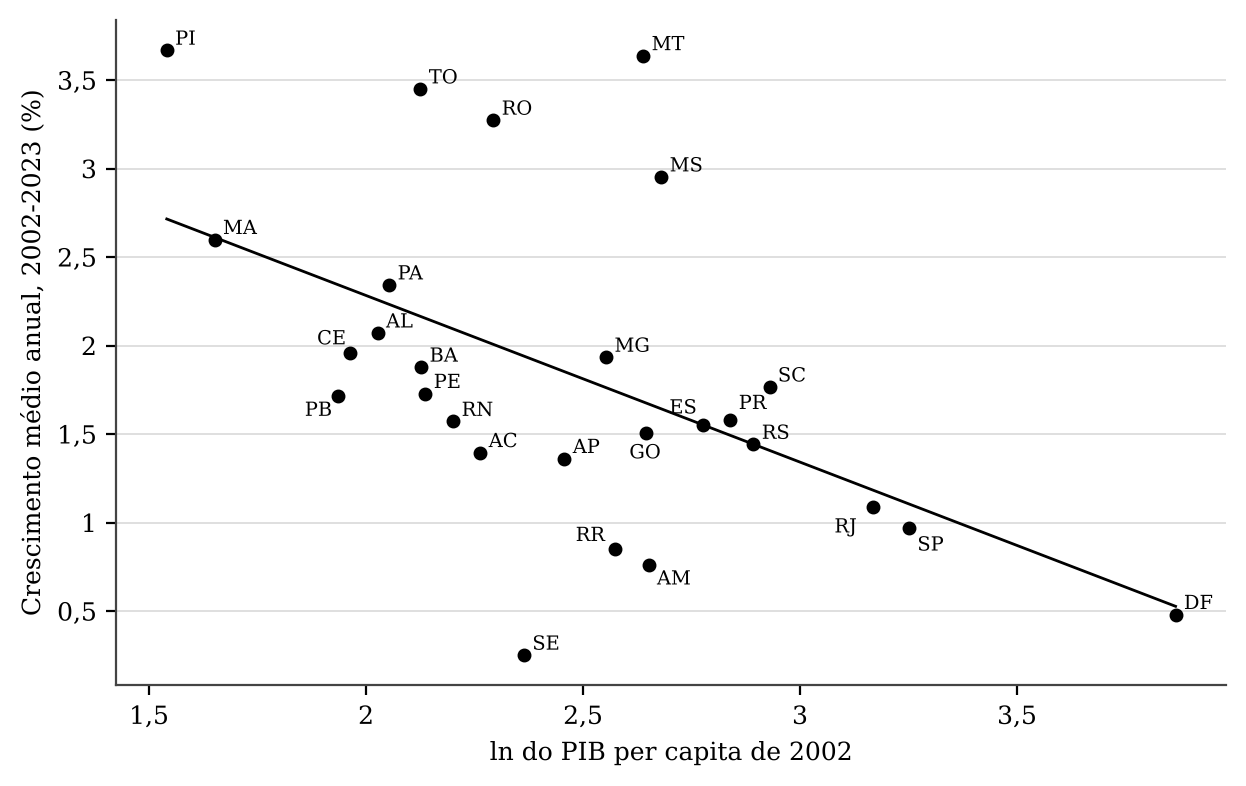

In [10]:
# ----------------------------------------------------------------------------
# 10. GRÁFICO DE DISPERSÃO (Figura 4 do trabalho escrito)
# ----------------------------------------------------------------------------
# Padrão das figuras do texto: preto e cinza, fonte serifada de 9 pt, vírgula decimal,
# sem título (título e fonte ficam no Word), no tamanho de impressão (16 cm = 6,3 pol.).
from matplotlib.ticker import FuncFormatter
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#444444"})
VIRG = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))

fig, ax = plt.subplots(figsize=(6.3, 4.0))

# Cada ponto é um estado: renda inicial no eixo x, crescimento médio no eixo y
ax.scatter(df_beta["ln_y0"], df_beta["cresc_medio"] * 100, s=16, color="black", zorder=3)

# Rótulo com a sigla ao lado de cada ponto (alguns deslocados para não se sobreporem)
desloc = {"ES": (-12, 4), "PR": (3, 4), "GO": (-6, -9), "RJ": (-14, -9), "SP": (3, -8),
          "RR": (-14, 3), "AM": (3, -7), "CE": (-12, 3), "PB": (-12, -7)}
for _, r in df_beta.iterrows():
    ax.annotate(r["Sigla"], (r["ln_y0"], r["cresc_medio"] * 100), fontsize=7,
                xytext=desloc.get(r["Sigla"], (3, 2)), textcoords="offset points")

# Reta ajustada: gera pontos no intervalo observado e aplica a equação estimada
grade = np.linspace(df_beta["ln_y0"].min(), df_beta["ln_y0"].max(), 100)
ajuste = mod_full.params["const"] + mod_full.params["ln_y0"] * grade
ax.plot(grade, ajuste * 100, color="black", lw=1, zorder=2)

ax.set_xlabel(f"ln do PIB per capita de {ANO_INICIAL}")
ax.set_ylabel(f"Crescimento médio anual, {ANO_INICIAL}-{ANO_FINAL} (%)")
ax.xaxis.set_major_formatter(VIRG); ax.yaxis.set_major_formatter(VIRG)
ax.grid(axis="y", color="#d9d9d9", lw=0.6, zorder=1)
plt.tight_layout()
plt.savefig("resultados/figuras/beta_convergencia.png", dpi=300, bbox_inches="tight")
plt.show()
plt.rcParams.update(plt.rcParamsDefault)   # o gráfico 10b segue no estilo anterior


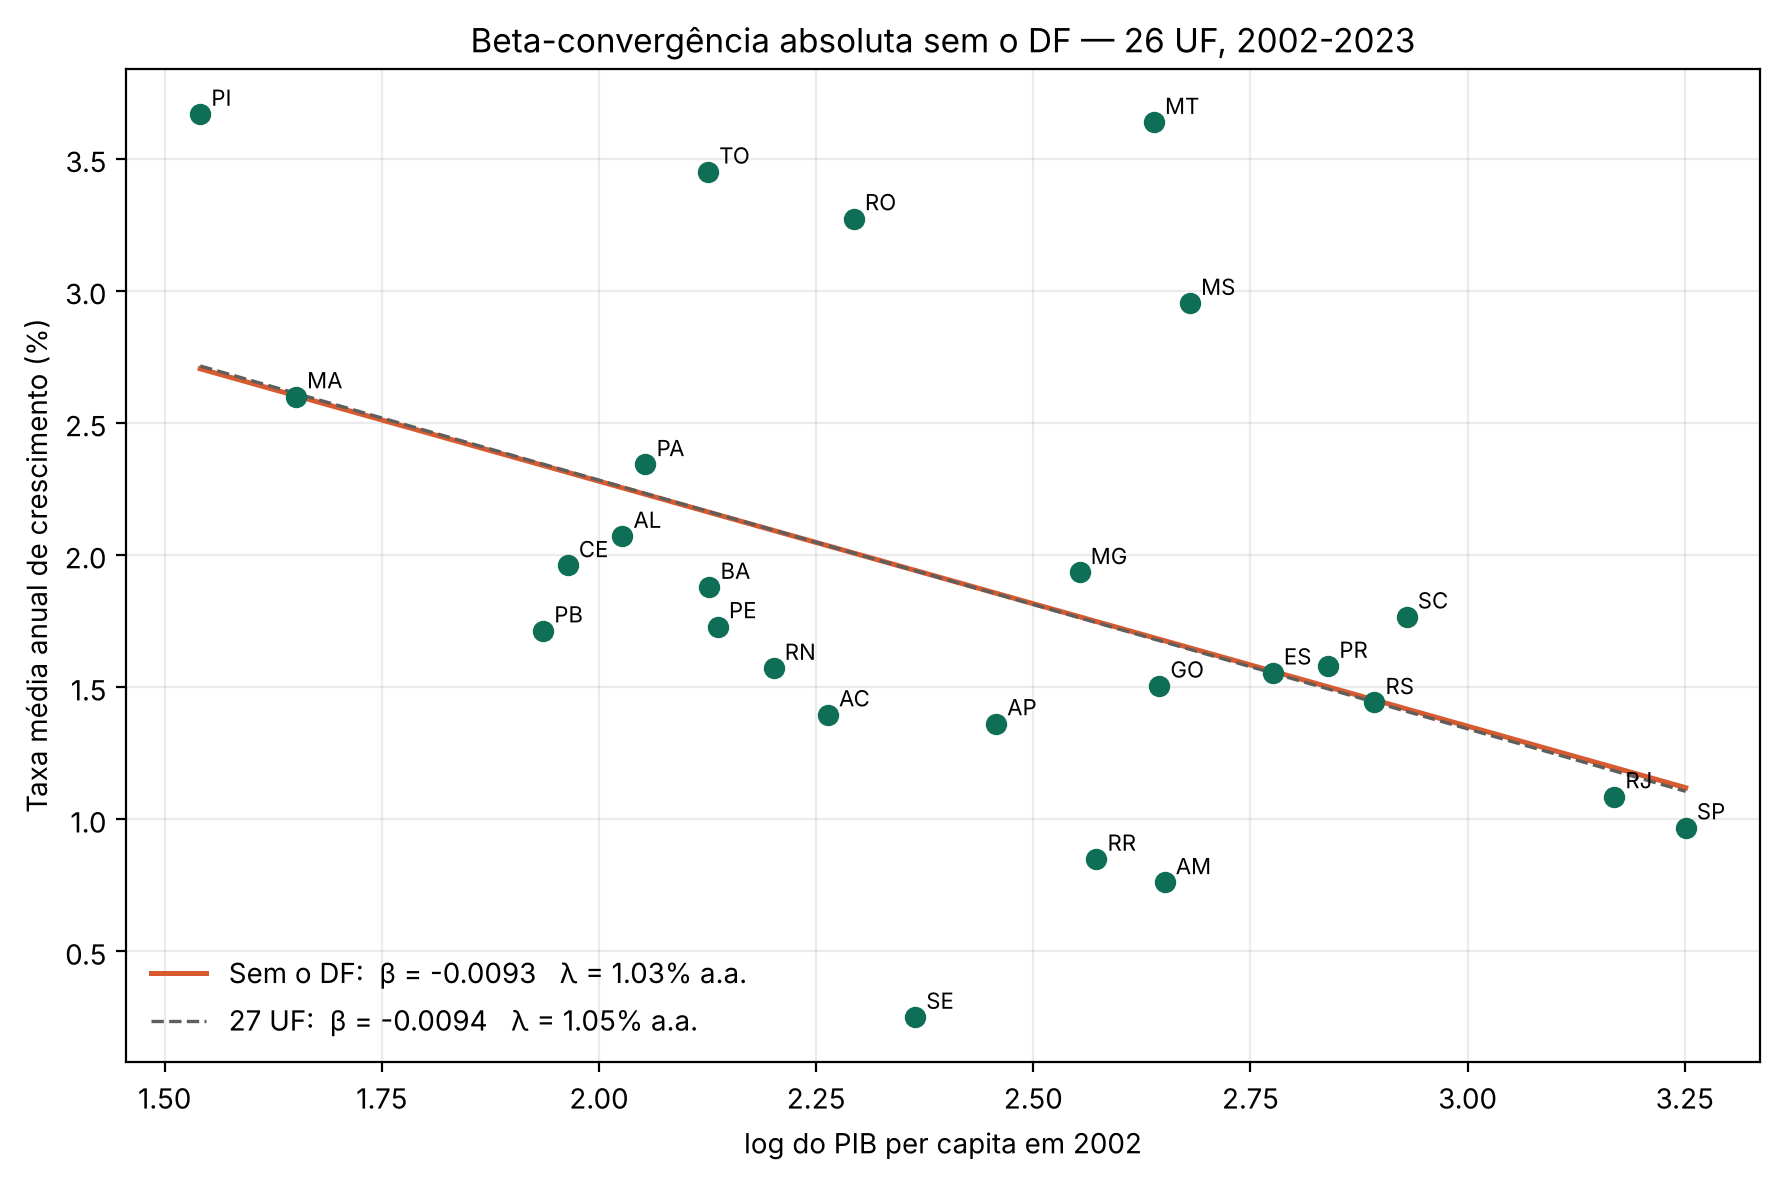

In [11]:
# ----------------------------------------------------------------------------
# 10b. GRÁFICO DE DISPERSÃO SEM O DF (robustez 1)
# ----------------------------------------------------------------------------
# Mesmo gráfico da célula anterior, agora com os 26 estados (sem o DF) e a reta
# estimada na robustez 1 (célula 6, res_sdf). O DF tinha a maior renda inicial,
# muito acima dos demais; sem ele, o eixo x fica mais curto.
# A reta tracejada é a das 27 UF, desenhada no mesmo intervalo, para comparação:
# se as duas quase coincidem, o resultado não depende do DF.
mod_sdf = res_sdf["modelo"]

fig, ax = plt.subplots(figsize=(9, 6))

# Cada ponto é um estado (26, sem o DF)
ax.scatter(sem_df["ln_y0"], sem_df["cresc_medio"] * 100,
           s=45, color="#0F6E56", zorder=3)

# Rótulo com a sigla ao lado de cada ponto
for _, r in sem_df.iterrows():
    ax.annotate(r["Sigla"], (r["ln_y0"], r["cresc_medio"] * 100),
                fontsize=8, xytext=(4, 3), textcoords="offset points")

# Reta ajustada SEM o DF, no intervalo observado dos 26 estados
grade_sdf = np.linspace(sem_df["ln_y0"].min(), sem_df["ln_y0"].max(), 100)
ajuste_sdf = mod_sdf.params["const"] + mod_sdf.params["ln_y0"] * grade_sdf
ax.plot(grade_sdf, ajuste_sdf * 100, color="#D85A30", lw=1.8, zorder=2,
        label=f"Sem o DF:  β = {res_sdf['b']:.4f}   λ = {res_sdf['lam']*100:.2f}% a.a.")

# Reta das 27 UF (estimada COM o DF), no mesmo intervalo, para comparação
ajuste_full_sdf = mod_full.params["const"] + mod_full.params["ln_y0"] * grade_sdf
ax.plot(grade_sdf, ajuste_full_sdf * 100, color="#5F5E5A", lw=1.2, ls="--", zorder=2,
        label=f"27 UF:  β = {res_full['b']:.4f}   λ = {res_full['lam']*100:.2f}% a.a.")

ax.set_xlabel(f"log do PIB per capita em {ANO_INICIAL}")
ax.set_ylabel("Taxa média anual de crescimento (%)")
ax.set_title(f"Beta-convergência absoluta sem o DF — 26 UF, {ANO_INICIAL}-{ANO_FINAL}")
ax.legend(frameon=False)
ax.grid(alpha=0.25, zorder=1)
plt.tight_layout()
plt.savefig("resultados/figuras/beta_convergencia_sem_df.png", dpi=200)
plt.show()

In [12]:
# ----------------------------------------------------------------------------
# 11. TABELA-RESUMO PARA O TEXTO
# ----------------------------------------------------------------------------
resultados = [res_full, res_sdf, res_rob, res_spi]

resumo = pd.DataFrame({
    "Especificação":              [r["rotulo"] for r in resultados],
    "n":                          [r["n"] for r in resultados],
    "τ":                          [r["tau"] for r in resultados],
    "β":                          [r["b"] for r in resultados],
    f"Erro-padrão ({TIPO_EP})":   [r["ep"] for r in resultados],
    "t":                          [r["t"] for r in resultados],
    "p-valor unilateral":         [r["p_unilateral"] for r in resultados],
    "Rejeita H0 a 5%":            [r["rejeita_5"] for r in resultados],
    "Rejeita H0 a 1%":            [r["rejeita_1"] for r in resultados],
    "p-valor (EP convencional)":  [r["p_unilateral_conv"] for r in resultados],
    "R²":                         [r["r2"] for r in resultados],
    "λ (% a.a.)":                 [r["lam"] * 100 for r in resultados],
    "λ IC95% inf":                [r["lam_inf"] * 100 for r in resultados],
    "λ IC95% sup":                [r["lam_sup"] * 100 for r in resultados],
    "Meia-vida (anos)":           [r["meia_vida"] for r in resultados],
    "Meia-vida IC95% inf":        [r["mv_inf"] for r in resultados],
    "Meia-vida IC95% sup":        [r["mv_sup"] for r in resultados],
})

print(resumo.round(4).to_string(index=False))

# Salva os produtos para reuso
df_beta.to_csv("dados/tratados/df_beta.csv", index=False)
painel.to_csv("dados/tratados/painel_uf.csv", index=False)
resumo.to_csv("resultados/tabelas/resumo_beta.csv", index=False)

                 Especificação  n  τ       β  Erro-padrão (HC3)       t  p-valor unilateral  Rejeita H0 a 5%  Rejeita H0 a 1%  p-valor (EP convencional)     R²  λ (% a.a.)  λ IC95% inf  λ IC95% sup  Meia-vida (anos)  Meia-vida IC95% inf  Meia-vida IC95% sup
                Todas as 27 UF 27 21 -0.0094             0.0021 -4.5288              0.0001             True             True                     0.0027 0.2706      1.0490       0.5432       1.6150           66.0787              42.9200             127.6155
                Excluindo o DF 26 21 -0.0093             0.0030 -3.1207              0.0023             True             True                     0.0108 0.2012      1.0312       0.3248       1.8609           67.2172              37.2471             213.3958
Base inicial = média 2002-2004 27 20 -0.0090             0.0022 -4.1384              0.0002             True             True                     0.0015 0.3005      0.9897       0.4727       1.5663           70.0377           